# PART 1 - SETUP

In [5]:
#@title Import Required Packages
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns



In [6]:
#@title Import Excel Sheets to DataFrames

pd.read_excel('pavingdata.xlsx', sheet_name=0)
resurface_df = pd.read_excel('pavingdata.xlsx', sheet_name=0)
pavement_df = pd.read_excel('pavingdata.xlsx', sheet_name=1)

In [7]:
print(resurface_df.head())
print(pavement_df.head())


   Work Schedule Project Location ID Borough Name       Day       Date  \
0                             254424        BRONX    Friday 2024-11-01   
1                             254165        BRONX  Thursday 2024-10-31   
2                             254420        BRONX    Friday 2024-11-01   
3                             254161        BRONX  Thursday 2024-10-31   
4                             254423        BRONX    Friday 2024-11-01   

   On Street Name From Street Name  To Street Name  Community Board  \
0  PUGSLEY AVENUE   GLEASON AVENUE   POWELL AVENUE            209.0   
1  PUGSLEY AVENUE   GLEASON AVENUE   POWELL AVENUE            209.0   
2   POWELL AVENUE   PUGSLEY AVENUE             NaN            209.0   
3   POWELL AVENUE   PUGSLEY AVENUE             NaN            209.0   
4  PUGSLEY AVENUE     ELLIS AVENUE  GLEASON AVENUE            209.0   

                 Area Work Type      Crew Type   Shift Type  \
0  Soundview-Bruckner    PAVING  IN-HOUSE CREW  NIGHT SHIFT   
1 

In [8]:
print(resurface_df.columns)
print(pavement_df.columns)

Index(['Work Schedule Project Location ID', 'Borough Name', 'Day', 'Date',
       'On Street Name', 'From Street Name', 'To Street Name',
       'Community Board', 'Area', 'Work Type', 'Crew Type', 'Shift Type',
       'OFTCode'],
      dtype='object')
Index(['the_geom', 'SegmentID', 'BoroughCod', 'OFTCode', 'OnStreetNa',
       'FromStreet', 'ToStreetNa', 'WKT', 'ManualRati', 'RatingLaye',
       'Inspection', 'Shape_STLe'],
      dtype='object')


# PART 2 - PAVEMENT RESURFACING JOBS

For these tasks, we will be analyzing the **resurface_df** dataframe.

In [9]:
#@title Review DataFrame Contents
print(resurface_df.head())
print(resurface_df.info())


   Work Schedule Project Location ID Borough Name       Day       Date  \
0                             254424        BRONX    Friday 2024-11-01   
1                             254165        BRONX  Thursday 2024-10-31   
2                             254420        BRONX    Friday 2024-11-01   
3                             254161        BRONX  Thursday 2024-10-31   
4                             254423        BRONX    Friday 2024-11-01   

   On Street Name From Street Name  To Street Name  Community Board  \
0  PUGSLEY AVENUE   GLEASON AVENUE   POWELL AVENUE            209.0   
1  PUGSLEY AVENUE   GLEASON AVENUE   POWELL AVENUE            209.0   
2   POWELL AVENUE   PUGSLEY AVENUE             NaN            209.0   
3   POWELL AVENUE   PUGSLEY AVENUE             NaN            209.0   
4  PUGSLEY AVENUE     ELLIS AVENUE  GLEASON AVENUE            209.0   

                 Area Work Type      Crew Type   Shift Type  \
0  Soundview-Bruckner    PAVING  IN-HOUSE CREW  NIGHT SHIFT   
1 

In [10]:
#@title Fix Community Board Column

# Run this cell to onvert the community board column to integers. Skip the NaNs

resurface_df['Community Board'] = pd.to_numeric(resurface_df['Community Board'], errors='coerce').astype('Int64')
resurface_df.head()


,Work Schedule Project Location ID,Borough Name,Day,Date,On Street Name,From Street Name,To Street Name,Community Board,Area,Work Type,Crew Type,Shift Type,OFTCode
0,254424,BRONX,Friday,2024-11-01,PUGSLEY AVENUE,GLEASON AVENUE,POWELL AVENUE,209,Soundview-Bruckner,PAVING,IN-HOUSE CREW,NIGHT SHIFT,259720000000000000
1,254165,BRONX,Thursday,2024-10-31,PUGSLEY AVENUE,GLEASON AVENUE,POWELL AVENUE,209,Soundview-Bruckner,PAVING,IN-HOUSE CREW,NIGHT SHIFT,259720000000000000
2,254420,BRONX,Friday,2024-11-01,POWELL AVENUE,PUGSLEY AVENUE,NaN,209,NaN,PAVING,IN-HOUSE CREW,NIGHT SHIFT,259220000000000000
3,254161,BRONX,Thursday,2024-10-31,POWELL AVENUE,PUGSLEY AVENUE,NaN,209,NaN,PAVING,IN-HOUSE CREW,NIGHT SHIFT,259220000000000000
4,254423,BRONX,Friday,2024-11-01,PUGSLEY AVENUE,ELLIS AVENUE,GLEASON AVENUE,209,Soundview-Bruckner,PAVING,IN-HOUSE CREW,NIGHT SHIFT,259720000000000000


In [11]:
#@title Edit Dates

resurface_df['Date'] = pd.to_datetime(resurface_df['Date'])
resurface_df.head()

,Work Schedule Project Location ID,Borough Name,Day,Date,On Street Name,From Street Name,To Street Name,Community Board,Area,Work Type,Crew Type,Shift Type,OFTCode
0,254424,BRONX,Friday,2024-11-01,PUGSLEY AVENUE,GLEASON AVENUE,POWELL AVENUE,209,Soundview-Bruckner,PAVING,IN-HOUSE CREW,NIGHT SHIFT,259720000000000000
1,254165,BRONX,Thursday,2024-10-31,PUGSLEY AVENUE,GLEASON AVENUE,POWELL AVENUE,209,Soundview-Bruckner,PAVING,IN-HOUSE CREW,NIGHT SHIFT,259720000000000000
2,254420,BRONX,Friday,2024-11-01,POWELL AVENUE,PUGSLEY AVENUE,NaN,209,NaN,PAVING,IN-HOUSE CREW,NIGHT SHIFT,259220000000000000
3,254161,BRONX,Thursday,2024-10-31,POWELL AVENUE,PUGSLEY AVENUE,NaN,209,NaN,PAVING,IN-HOUSE CREW,NIGHT SHIFT,259220000000000000
4,254423,BRONX,Friday,2024-11-01,PUGSLEY AVENUE,ELLIS AVENUE,GLEASON AVENUE,209,Soundview-Bruckner,PAVING,IN-HOUSE CREW,NIGHT SHIFT,259720000000000000


In [12]:
#@title Number of Paving Jobs per Bourough Name and Work Type
borough_work_counts = (
    resurface_df
    .groupby(['Borough Name', 'Work Type'])
    .size()
    .reset_index(name='Job Count')
)

borough_work_counts



,Borough Name,Work Type,Job Count
0,BRONX,MILLING,216
1,BRONX,PAVING,601
2,BROOKLYN,MILLING,776
3,BROOKLYN,PAVING,682
4,MANHATTAN,MILLING,382
5,MANHATTAN,PAVING,82
6,QUEENS,MILLING,537
7,QUEENS,PAVING,416
8,STATEN ISLAND,MILLING,2
9,STATEN ISLAND,PAVING,582


In [28]:
# Alternate method
borough_work_counts = (
    resurface_df
    .groupby(['Borough Name', 'Work Type'])
    .size()
    .reset_index()
)
borough_work_counts.columns = ['Borough Name', 'Work Type', 'Job Count']
borough_work_counts

,Borough Name,Work Type,Job Count
0,BRONX,MILLING,216
1,BRONX,PAVING,601
2,BROOKLYN,MILLING,776
3,BROOKLYN,PAVING,682
4,MANHATTAN,MILLING,382
5,MANHATTAN,PAVING,82
6,QUEENS,MILLING,537
7,QUEENS,PAVING,416
8,STATEN ISLAND,MILLING,2
9,STATEN ISLAND,PAVING,582


In [14]:
#@title Common Names

# Using groupby
street_counts = (
    resurface_df
    .groupby('On Street Name')
    .size()
)
street_counts = (
    resurface_df
    .groupby('On Street Name')
    .size()
    .reset_index(name='Job Count')
)
street_counts = street_counts.sort_values(
    by='Job Count',
    ascending=False
)
street_counts.head(10)

,On Street Name,Job Count
89,4 AVENUE,286
178,ARTHUR KILL ROAD,190
444,RICHMOND AVENUE,152
204,BAY RIDGE PARKWAY,128
442,REMSEN AVENUE,125
221,BOWERY,98
297,EAST 222 STREET,91
168,ADEE AVENUE,85
57,19 AVENUE,81
482,WEST 6 STREET,65


In [15]:
# Alternate method using value_counts()

street_counts_vc = (
    resurface_df['On Street Name']
    .value_counts()
    .reset_index()
)
street_counts_vc.columns = ['Street Name', 'Job Count']
street_counts_vc.head(10)

,Street Name,Job Count
0,4 AVENUE,286
1,ARTHUR KILL ROAD,190
2,RICHMOND AVENUE,152
3,BAY RIDGE PARKWAY,128
4,REMSEN AVENUE,125
5,BOWERY,98
6,EAST 222 STREET,91
7,ADEE AVENUE,85
8,19 AVENUE,81
9,WEST 6 STREET,65


In [27]:
#@title Work Hours
street_counts = (
    resurface_df
    .groupby('Shift Type')
    .size()
    .reset_index(name='Job Count')
)
street_counts

,Shift Type,Job Count
0,DAY SHIFT,2381
1,NIGHT SHIFT,1895


In [17]:
#@title Work Jobs by Borough
borough_counts = resurface_df['Borough Name'].value_counts()



In [18]:
print(borough_counts)

Borough Name
BROOKLYN         1458
QUEENS            953
BRONX             817
STATEN ISLAND     584
MANHATTAN         464
Name: count, dtype: int64


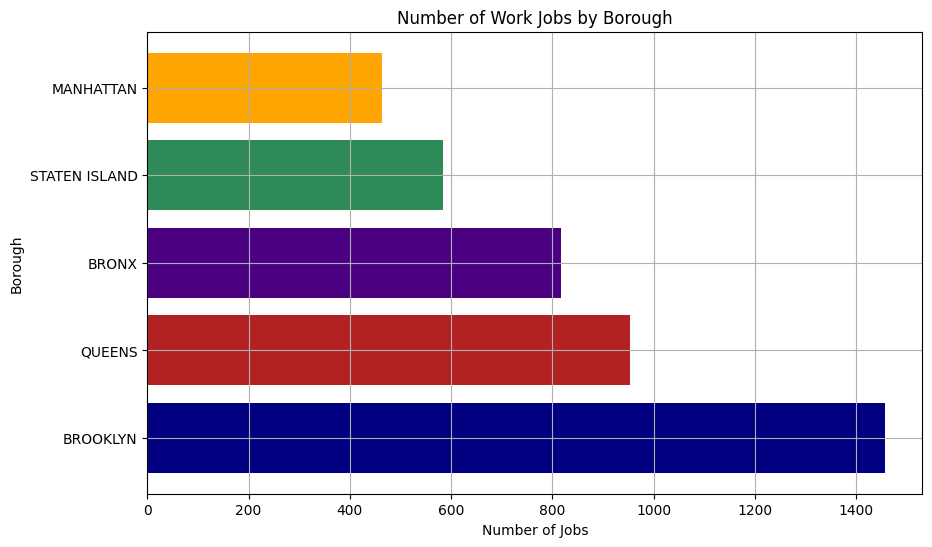

In [19]:
plt.figure(figsize=(10,6))

plt.barh(
    borough_counts.index,
    borough_counts.values,
    color=['navy', 'firebrick', 'indigo', 'seagreen', 'orange']
)

plt.title('Number of Work Jobs by Borough')
plt.xlabel('Number of Jobs')
plt.ylabel('Borough')

plt.grid(True)

plt.show()

## PART 3 - PAVEMENT RATING

For these tasks, we will be analyzing the **pavement_df** dataframe.

In [20]:
# Display the first few rows here
pavement_df.head()


,the_geom,SegmentID,BoroughCod,OFTCode,OnStreetNa,FromStreet,ToStreetNa,WKT,ManualRati,RatingLaye,Inspection,Shape_STLe
0,MULTILINESTRING ((-74.11666642623013 40.631710...,12580,S,547450520450525908,SENECA STREET,BROADWAY,DEAD END,LINESTRING (952497.39720000327 169543.64180000...,8,GOOD,2019-04-04,480.329616
1,MULTILINESTRING ((-73.76053511829863 40.752054...,101081,Q,426850411640412040,219 STREET,56 AVENUE,58 AVENUE,LINESTRING (1050597.0930999964 213361.13490000...,9,GOOD,2025-01-17,701.730255
2,MULTILINESTRING ((-74.15081424919451 40.621472...,8579,S,551110525908533197,TIGER COURT,DEAD END,HOLIDAY DRIVE,LINESTRING (942382.86399999261 165731.55979999...,7,FAIR,2018-03-20,143.263383
3,MULTILINESTRING ((-74.16424181484899 40.621950...,5438,S,547436536615556197,SELVIN LOOP,LISK AVENUE,WOLKOFF LANE,LINESTRING (938702.87790000439 166161.90340000...,8,GOOD,2013-05-10,253.988192
4,MULTILINESTRING ((-74.01962203718749 40.642501...,17793,B,305280309530309580,3 AVENUE,59 STREET,60 STREET,LINESTRING (978745.47059999406 173401.81649999...,8,GOOD,2025-01-18,267.263324


In [21]:
#@title Borough Name Mapping
borough_mapping = {
    'X': 'Bronx',
    'B': 'Brooklyn',
    'M': 'Manhattan',
    'Q': 'Queens',
    'S': 'Staten Island'
}

pavement_df['Borough'] = pavement_df['BoroughCod'].map(borough_mapping)

pavement_df.head()

,the_geom,SegmentID,BoroughCod,OFTCode,OnStreetNa,FromStreet,ToStreetNa,WKT,ManualRati,RatingLaye,Inspection,Shape_STLe,Borough
0,MULTILINESTRING ((-74.11666642623013 40.631710...,12580,S,547450520450525908,SENECA STREET,BROADWAY,DEAD END,LINESTRING (952497.39720000327 169543.64180000...,8,GOOD,2019-04-04,480.329616,Staten Island
1,MULTILINESTRING ((-73.76053511829863 40.752054...,101081,Q,426850411640412040,219 STREET,56 AVENUE,58 AVENUE,LINESTRING (1050597.0930999964 213361.13490000...,9,GOOD,2025-01-17,701.730255,Queens
2,MULTILINESTRING ((-74.15081424919451 40.621472...,8579,S,551110525908533197,TIGER COURT,DEAD END,HOLIDAY DRIVE,LINESTRING (942382.86399999261 165731.55979999...,7,FAIR,2018-03-20,143.263383,Staten Island
3,MULTILINESTRING ((-74.16424181484899 40.621950...,5438,S,547436536615556197,SELVIN LOOP,LISK AVENUE,WOLKOFF LANE,LINESTRING (938702.87790000439 166161.90340000...,8,GOOD,2013-05-10,253.988192,Staten Island
4,MULTILINESTRING ((-74.01962203718749 40.642501...,17793,B,305280309530309580,3 AVENUE,59 STREET,60 STREET,LINESTRING (978745.47059999406 173401.81649999...,8,GOOD,2025-01-18,267.263324,Brooklyn


In [22]:
#@title Average Rating
average_ratings = (
    pavement_df
    .groupby(['RatingLaye', 'Borough'])['ManualRati']
    .mean()
)

average_ratings



RatingLaye  Borough      
FAIR        Bronx            6.148649
            Brooklyn         6.255256
            Manhattan        6.400000
            Queens           6.067364
            Staten Island    6.170732
GOOD        Bronx            8.450331
            Brooklyn         8.381886
            Manhattan        8.365854
            Queens           8.411613
            Staten Island    8.423963
POOR        Bronx            2.800000
            Brooklyn         2.632479
            Queens           2.714286
            Staten Island    2.684211
Name: ManualRati, dtype: float64

In [23]:
#@title Multiple Grouping and Aggregation

inspection_summary = (
    pavement_df
    .groupby([
        'Inspection',
        'RatingLaye',
        'Borough'
    ])
    .agg({
        'ManualRati': 'mean',
        'BoroughCod': 'count'
    })
)

inspection_summary

ManualRati  BoroughCod
Inspection RatingLaye Borough                         
2002-04-02 FAIR       Brooklyn    7.000000           4
2002-06-24 GOOD       Brooklyn    8.000000           2
2002-08-14 FAIR       Queens      6.000000           1
           GOOD       Queens      8.000000           2
2002-11-04 GOOD       Queens      8.000000           6
...                                    ...         ...
2025-02-27 POOR       Brooklyn    3.000000           2
2025-02-28 FAIR       Brooklyn    6.166667          18
           GOOD       Brooklyn    8.210526          19
2025-03-02 FAIR       Brooklyn    6.142857           7
           GOOD       Brooklyn    8.000000           3

[2334 rows x 2 columns]

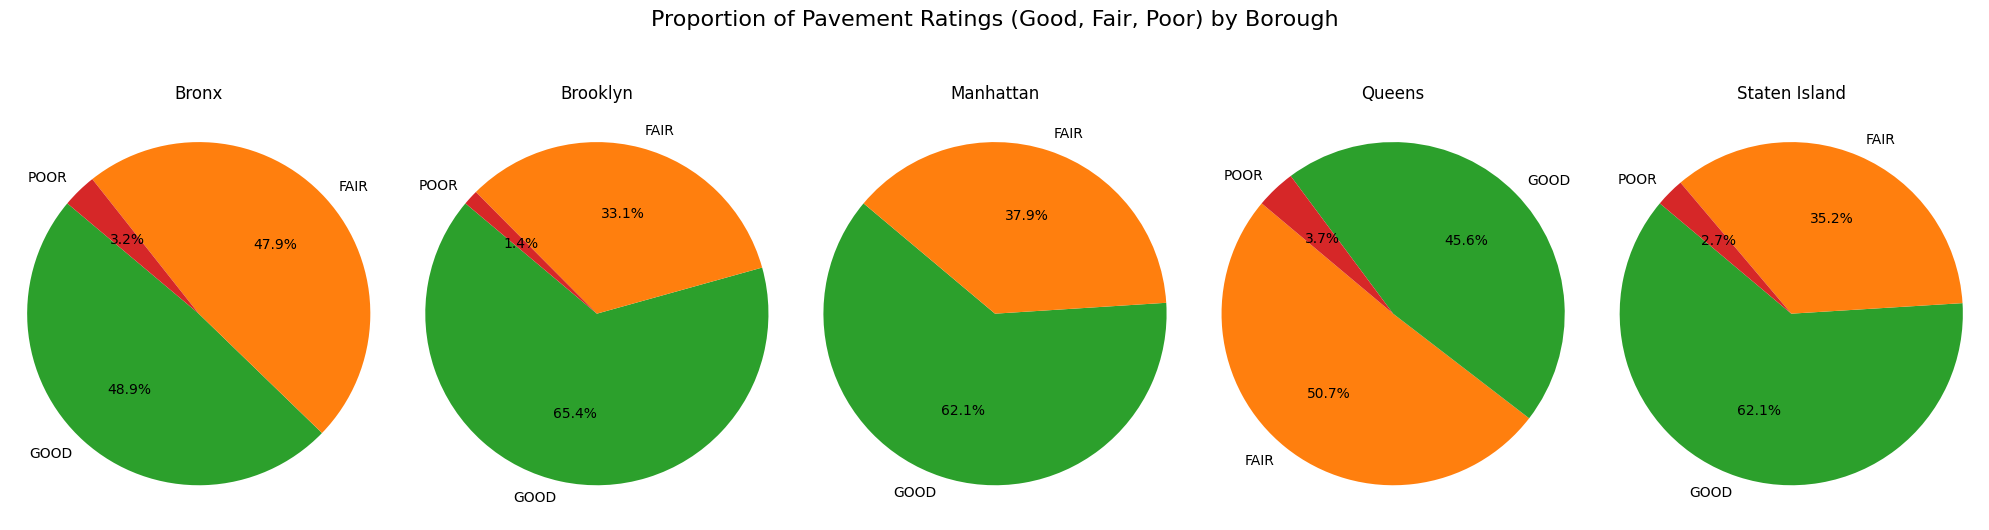

In [25]:

boroughs = pavement_df['Borough'].dropna().unique()

fig, axes = plt.subplots(1, 5, figsize=(20, 5))

colors = {'GOOD': '#2ca02c', 'FAIR': '#ff7f0e', 'POOR': '#d62728'}

for i, borough in enumerate(sorted(boroughs)):
    sub_df = pavement_df[pavement_df['Borough'] == borough]
    rating_counts = sub_df['RatingLaye'].value_counts()

    pie_colors = [colors.get(cat, '#cccccc') for cat in rating_counts.index]

    axes[i].pie(
        rating_counts.values,
        labels=rating_counts.index,
        autopct='%1.1f%%',
        startangle=140,
        colors=pie_colors
    )
    axes[i].set_title(borough)
    axes[i].axis('equal')

plt.suptitle('Proportion of Pavement Ratings (Good, Fair, Poor) by Borough', fontsize=16, y=1.05)
plt.tight_layout()
plt.show()